In [1]:
library(dplyr)
library(Seurat)
library(ggplot2)
library(scDblFinder)
library(SingleCellExperiment)
library(patchwork)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.


Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘matrixStats’


The following object is masked from ‘package:dplyr’

In [2]:
proc_path = '../ProcessedData'
proc_files <- list.files(proc_path, full.names = TRUE, pattern = "_P01.rds$|_P02.rds$|_P03.rds$|_P06.rds$")

processed_files <- lapply(proc_files, function(file){
    readRDS(file)
})

names(processed_files) <- sub(
    ".rds$",
    "",
    basename(proc_files)
)

In [3]:
for(i in seq_along(processed_files)) {

    sample_name <- names(processed_files)[i]

    if(grepl("_P01$|_P02$", sample_name)) {
        processed_files[[i]]$treatment <- "Untreated"
    }

    if(grepl("_P03$|_P06$", sample_name)) {
        processed_files[[i]]$treatment <- "Treated"
    }
}

In [4]:
pre_chemo <- Filter(
    function(x) unique(x$treatment) == "Untreated",
    processed_files
)

post_chemo <- Filter(
    function(x) unique(x$treatment) == "Treated",
    processed_files
)

In [5]:
pre_chemo

$GSM6204109_P01
An object of class Seurat 
23650 features across 4680 samples within 1 assay 
Active assay: RNA (23650 features, 2000 variable features)
 2 layers present: counts, data

$GSM6204110_P02
An object of class Seurat 
23307 features across 3340 samples within 1 assay 
Active assay: RNA (23307 features, 2000 variable features)
 2 layers present: counts, data


In [6]:
integration_features_prechemo <- SelectIntegrationFeatures(pre_chemo, nfeatures=2000)

anchors_prechemo <- FindIntegrationAnchors(pre_chemo, anchor.features = integration_features_prechemo, dims=1:30)


Warning message in CheckDuplicateCellNames(object.list = object.list):
“Some cell names are duplicated across objects provided. Renaming to enforce unique cell names.”
Scaling features for provided objects

Finding all pairwise anchors

Running CCA

Using RSpectra for CCA since the cell-by-cell cross-product matrix has at least 1,000,000 entries.
To use irlba, set `svd.method = "irlba"`
Merging objects

Finding neighborhoods

Finding anchors

	Found 7559 anchors

Filtering anchors

	Retained 5226 anchors



In [7]:
prechemo_integrated <- IntegrateData(anchors_prechemo, dims=1:30) 

Merging dataset 2 into 1

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”


In [8]:
DefaultAssay(prechemo_integrated) <- "integrated"

In [9]:
prechemo_integrated <- ScaleData(prechemo_integrated)
prechemo_integrated <- RunPCA(prechemo_integrated, npcs=30)

Centering and scaling data matrix

PC_ 1 
Positive:  LGALS4, MAL2, GPRC5A, KRT8, KRT19, KRT18, MUC1, CD24, FXYD3, TM4SF4 
	   TACSTD2, SPINK1, KRT7, CTSE, TSPAN8, CLDN4, TM4SF1, CYSTM1, CLDN1, TFF1 
	   TSPAN1, CXCL17, SLPI, CAMK2N1, IFI27, MUC20, OCLN, AGR2, CDH1, LCN2 
Negative:  TYROBP, S100A4, FCER1G, ZEB2, HLA-DRB1, LGALS1, HLA-DRA, CD74, AIF1, HLA-DPA1 
	   IFI30, MS4A7, SPP1, BCL2A1, PLEK, GPNMB, PLXDC2, FCGR3A, CYBB, S100A9 
	   LY96, KCTD12, SPI1, CD69, MAFB, CD83, CD14, LST1, OLR1, CLEC7A 
PC_ 2 
Positive:  CD69, CCL5, GZMA, KLRB1, IL7R, TRBC1, NKG7, LTB, GZMK, IL2RB 
	   KLRD1, ISG20, GZMH, KLRF1, FKBP11, XCL2, XCL1, IFNG, CD8B, TRDC 
	   CCL4, TNFRSF4, GZMB, BIRC3, GNLY, SPON2, CD160, KLRC1, TNFRSF18, DUSP4 
Negative:  CD68, PSAP, LYZ, FTL, CTSD, CTSB, IFI30, TIMP2, GLUL, CTSZ 
	   GPNMB, LIPA, CTSS, MS4A7, CD9, AIF1, ASAH1, MSR1, PLXDC2, LGMN 
	   CYBB, FPR3, KCTD12, DAB2, HLA-DRA, MAFB, CD14, APOC1, OLR1, PLAUR 
PC_ 3 
Positive:  SPARC, COL4A1, IGFBP7, COL4A2, CNN3, GNG11

In [10]:
prechemo_integrated <- RunUMAP(prechemo_integrated, dims=1:30, n.neighbors=30, min.dist=0.3)

16:43:20 UMAP embedding parameters a = 0.9922 b = 1.112

16:43:20 Read 8020 rows and found 30 numeric columns

16:43:20 Using Annoy for neighbor search, n_neighbors = 30

16:43:20 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:43:20 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//RtmpB9bf5V/file65607446dcf9

16:43:20 Searching Annoy index using 1 thread, search_k = 3000

16:43:21 Annoy recall = 100%

16:43:22 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:43:23 Initializing from normalized Laplacian + noise (using RSpectra)

16:43:23 Commencing optimization for 500 epochs, with 344334 positive edges

16:43:23 Using rng type: pcg

16:43:30 Optimization finished



In [11]:
prechemo_integrated <- FindNeighbors(prechemo_integrated, dims=1:30)

Computing nearest neighbor graph

Computing SNN



In [12]:
prechemo_integrated <- FindClusters(prechemo_integrated, resolution=0.3, algorithm=3)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 8020
Number of edges: 333083

Running smart local moving algorithm...
Maximum modularity in 10 random starts: 0.9303
Number of communities: 14
Elapsed time: 3 seconds


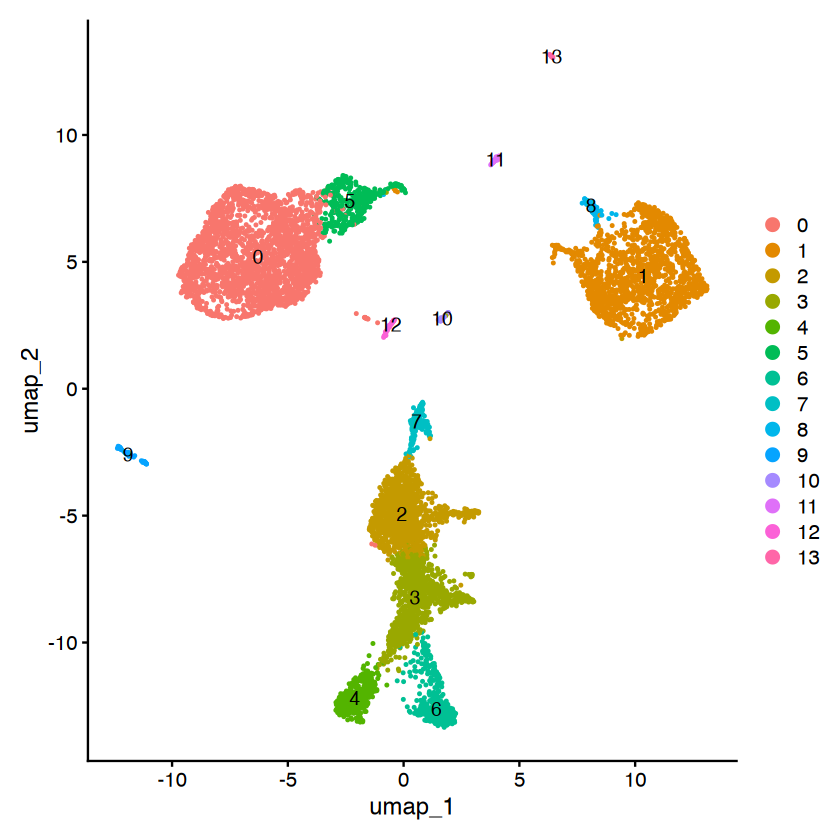

In [13]:
DimPlot(prechemo_integrated, reduction="umap", label=TRUE)

In [14]:
DefaultAssay(prechemo_integrated) <- "RNA"

prechemo_integrated <- JoinLayers(prechemo_integrated, assay = "RNA")

prechemo_markers <- FindAllMarkers(prechemo_integrated, only.pos=TRUE, min.pct = 0.25, logfc.threshold = 0.25, test.use='wilcox')

Calculating marker statistics for 14 clusters using presto

  Calculating fold changes

  Running presto::wilcoxauc



In [15]:
top10_prechemo <- prechemo_markers %>%
    group_by(cluster) %>%
    slice_max(
        order_by = avg_log2FC,
        n = 10,
        with_ties = FALSE
    )

In [16]:
View(top10_prechemo)

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0.000000e+00,5.545986,0.447,0.035,0.000000e+00,0,CEACAM5
0.000000e+00,5.428709,0.566,0.039,0.000000e+00,0,LINC01559
9.501900e-299,5.118484,0.297,0.022,2.395334e-294,0,DUOXA2
0.000000e+00,4.858306,0.309,0.015,0.000000e+00,0,HIF3A
0.000000e+00,4.641820,0.366,0.020,0.000000e+00,0,FUT3
0.000000e+00,4.606234,0.340,0.018,0.000000e+00,0,MUC4
0.000000e+00,4.583749,0.626,0.041,0.000000e+00,0,GULP1
7.524535e-276,4.570473,0.264,0.016,1.896860e-271,0,FAM155A
7.086339e-287,4.547173,0.267,0.014,1.786395e-282,0,FUT6


Warning message in DoHeatmap(prechemo_integrated, features = unique(top10_prechemo$gene), :
“The following features were omitted as they were not found in the scale.data layer for the RNA assay: LINC02812, LINC01724, PLA2G5, FOXC2, CD19, FCRL1, PAX5, NOVA2, HSPA12B, CCDC26, LINC01943, LINC02694, LINC00299, PRF1, CHST2, S1PR5, SH2D1B, NCAM1, TOX2, NCR1, AC017104.1, DUSP2, CD3E, GPR171, THEMIS, KLRG1, TRGC2, CD8A, CD5, CD28, TNFRSF25, CD40LG, LEF1, TRABD2A, MAL, PTPRR, FUT6, FAM155A, FUT3, HIF3A”


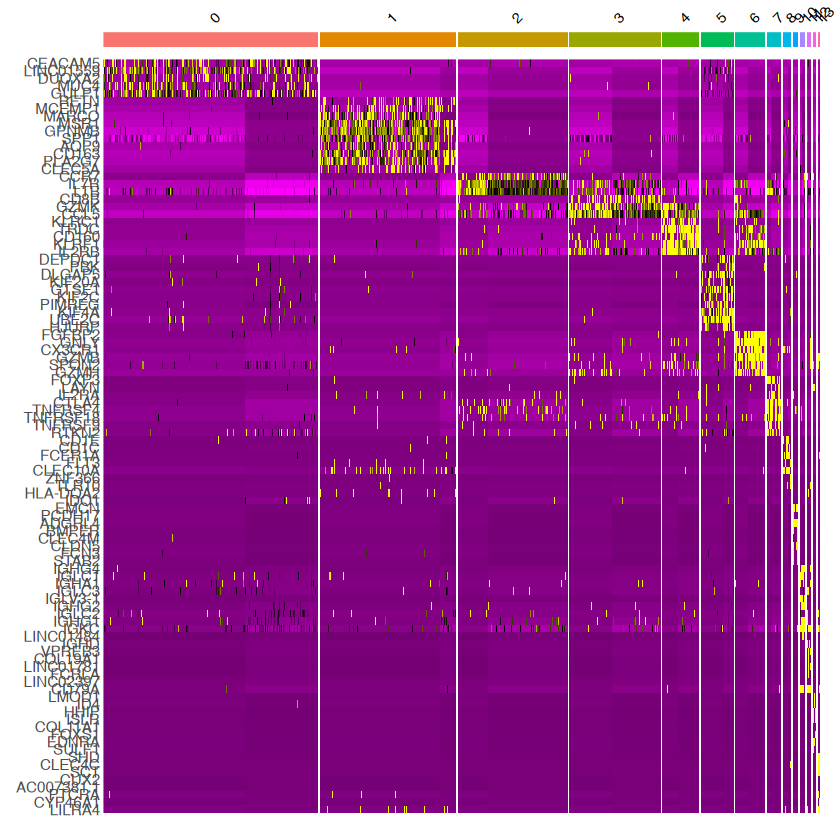

In [17]:
DoHeatmap(
    prechemo_integrated,
    features = unique(top10_prechemo$gene),
    group.by = "seurat_clusters",
    size = 3
) + NoLegend()

Warning message in DoHeatmap(object = prechemo_subset, features = unique(top5_prechemo$gene), :
“The following features were omitted as they were not found in the scale.data layer for the RNA assay: LINC01724, PAX5, NOVA2, HSPA12B, TOX2, NCR1, AC017104.1, KLRG1, TRGC2, CD8A, CD40LG, LEF1, TRABD2A, MAL, FUT3, HIF3A”
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


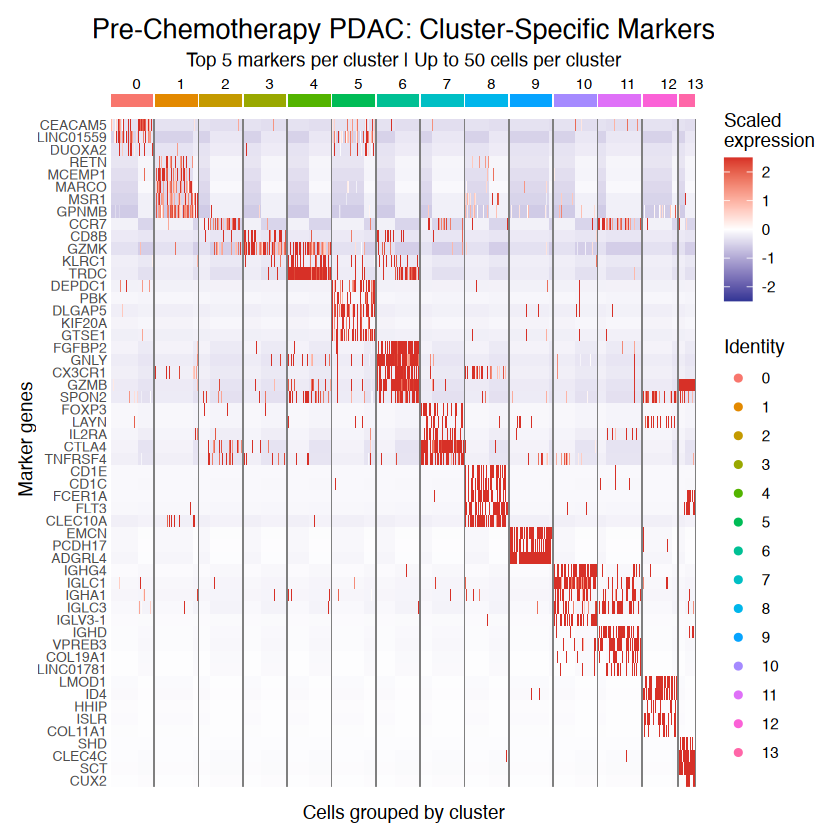

In [ ]:
# Select top 5 significant markers per cluster
top5_prechemo <- prechemo_markers %>%
    filter(p_val_adj < 0.05) %>%
    group_by(cluster) %>%
    slice_max(
        order_by = avg_log2FC,
        n = 5,
        with_ties = FALSE
    ) %>%
    ungroup()

# Randomly sample up to 50 cells from each cluster
set.seed(42)

prechemo_subset <- subset(
    prechemo_integrated,
    downsample = 50
)

# Plot heatmap
p <- DoHeatmap(
    object = prechemo_subset,
    features = unique(top5_prechemo$gene),
    assay = "RNA",
    group.by = "seurat_clusters",
    size = 3,
    angle = 0,
    raster = TRUE
) +
    scale_fill_gradientn(
        colors = c("#313695", "#FFFFFF", "#D73027"),
        limits = c(-2.5, 2.5),
        oob = scales::squish
    ) +
    labs(
        title = "Pre-Chemotherapy PDAC: Cluster-Specific Markers",
        subtitle = "Top 5 markers per cluster | Up to 50 cells per cluster",
        x = "Cells grouped by cluster",
        y = "Marker genes",
        fill = "Scaled\nexpression"
    ) +
    theme(
        plot.title = element_text(
            size = 16, face = "bold", hjust = 0.5
        ),
        plot.subtitle = element_text(
            size = 11, hjust = 0.5
        ),
        axis.text.y = element_text(size = 8),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title = element_text(size = 11),
        legend.position = "right"
    )

p

In [19]:
top10_prechemo <- prechemo_markers %>%
    filter(
        p_val_adj < 0.05,
        avg_log2FC > 0.25
    ) %>%
    group_by(cluster) %>%
    slice_max(
        order_by = avg_log2FC,
        n = 10,
        with_ties = FALSE
    ) %>%
    ungroup()

# Print markers for each cluster
top10_prechemo %>%
    select(cluster, gene, avg_log2FC, pct.1, pct.2, p_val_adj) %>%
    print(n = Inf)

# A tibble: 140 × 6
    cluster gene       avg_log2FC pct.1 pct.2 p_val_adj
    <fct>   <chr>           <dbl> <dbl> <dbl>     <dbl>
  1 0       CEACAM5          5.55 0.447 0.035 0        
  2 0       LINC01559        5.43 0.566 0.039 0        
  3 0       DUOXA2           5.12 0.297 0.022 2.40e-294
  4 0       HIF3A            4.86 0.309 0.015 0        
  5 0       FUT3             4.64 0.366 0.02  0        
  6 0       MUC4             4.61 0.34  0.018 0        
  7 0       GULP1            4.58 0.626 0.041 0        
  8 0       FAM155A          4.57 0.264 0.016 1.90e-271
  9 0       FUT6             4.55 0.267 0.014 1.79e-282
 10 0       PTPRR            4.53 0.252 0.014 6.49e-264
 11 1       RETN             8.47 0.33  0.003 0        
 12 1       MCEMP1           7.95 0.443 0.007 0        
 13 1       MARCO            7.89 0.566 0.011 0        
 14 1       MSR1             7.70 0.686 0.013 0        
 15 1       GPNMB            7.62 0.819 0.05  0        
 16 1       SPP1            

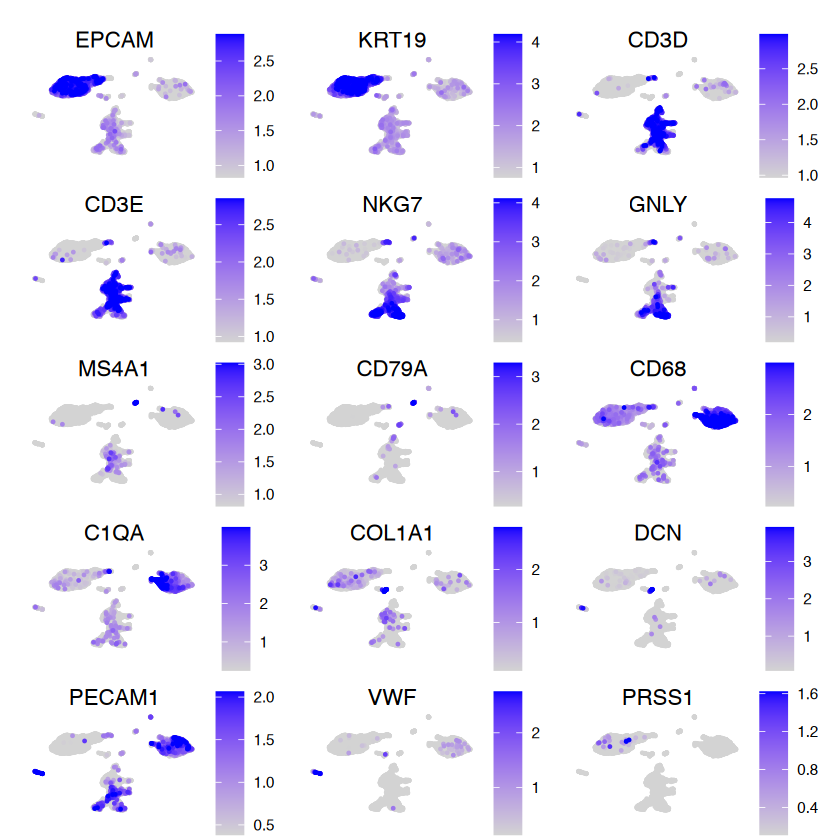

In [ ]:
DefaultAssay(prechemo_integrated) <- "RNA"

markers <- c(
    "EPCAM", "KRT19",
    "CD3D", "CD3E",
    "NKG7", "GNLY",
    "MS4A1", "CD79A",
    "CD68", "C1QA",
    "COL1A1", "DCN",
    "PECAM1", "VWF",
    "PRSS1", "CPA1"
)

markers <- intersect(
    markers,
    rownames(prechemo_integrated)
)

p <- FeaturePlot(
    object = prechemo_integrated,
    features = markers,
    reduction = "umap",
    ncol = 3,
    order = TRUE,
    pt.size = 0.15,
    min.cutoff = "q05",
    max.cutoff = "q95",
    combine = FALSE
)

# Style each individual UMAP
p <- lapply(p, function(plot) {
    plot +
        NoAxes() +
        theme_void() +
        theme(
            plot.title = element_text(
                size = 13,
                face = "bold",
                hjust = 0.5
            ),
            legend.position = "right",
            plot.margin = margin(8, 8, 8, 8)
        )
})

# Combine into a grid
final_plot <- wrap_plots(p, ncol = 3)

final_plot

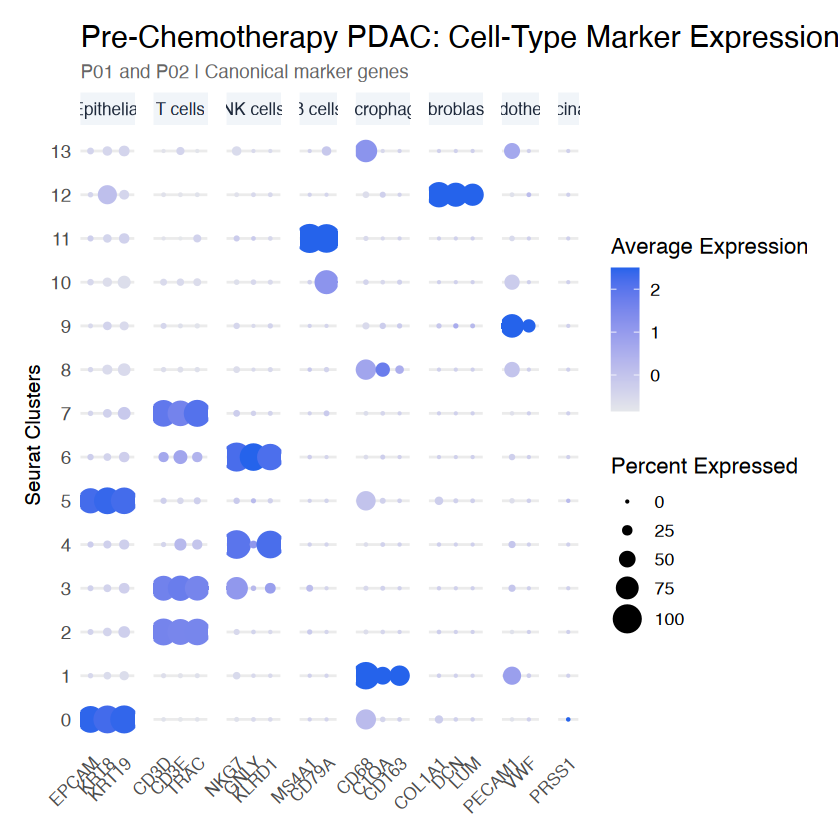

In [21]:
library(Seurat)
library(ggplot2)

celltype_markers <- list(
    "Epithelial"  = c("EPCAM", "KRT8", "KRT19"),
    "T cells"     = c("CD3D", "CD3E", "TRAC"),
    "NK cells"    = c("NKG7", "GNLY", "KLRD1"),
    "B cells"     = c("MS4A1", "CD79A"),
    "Macrophages" = c("CD68", "C1QA", "CD163"),
    "Fibroblasts" = c("COL1A1", "DCN", "LUM"),
    "Endothelial" = c("PECAM1", "VWF"),
    "Acinar"      = c("PRSS1")
)

# Retain genes present in the dataset
celltype_markers <- lapply(
    celltype_markers,
    function(x) intersect(x, rownames(prechemo_integrated))
)

celltype_markers <- Filter(
    function(x) length(x) > 0,
    celltype_markers
)

p_dot <- DotPlot(
    object = prechemo_integrated,
    features = celltype_markers,  # Keep cell-type groupings!
    assay = "RNA",
    group.by = "seurat_clusters",
    dot.scale = 7,
    cols = c("#E5E7EB", "#2563EB")
) +
    labs(
        title = "Pre-Chemotherapy PDAC: Cell-Type Marker Expression",
        subtitle = "P01 and P02 | Canonical marker genes",
        x = NULL,
        y = "Seurat Clusters",
        color = "Average\nExpression",
        size = "Percent\nExpressed"
    ) +
    theme_minimal(base_size = 13) +
    theme(
        plot.title = element_text(
            size = 18,
            face = "bold"
        ),
        plot.subtitle = element_text(
            size = 11,
            color = "grey40"
        ),
        strip.text.x = element_text(
            size = 10,
            face = "bold",
            color = "#1E293B"
        ),
        strip.background = element_rect(
            fill = "#F1F5F9",
            color = NA
        ),
        axis.text.x = element_text(
            angle = 45,
            hjust = 1,
            vjust = 1,
            size = 10,
            face = "bold"
        ),
        axis.text.y = element_text(size = 11),
        axis.title.y = element_text(
            size = 12,
            face = "bold"
        ),
        panel.grid.major.x = element_blank(),
        panel.grid.minor = element_blank(),
        panel.spacing.x = unit(0.8, "lines"),
        legend.position = "right",
        plot.margin = margin(15, 15, 15, 15)
    )

p_dot

In [22]:
cluster_annotations <- c(
    "0"  = "Epithelial",
    "1"  = "SPP1+ Macrophages",
    "2"  = "CD4-like T cells",
    "3"  = "CD8+ T cells",
    "4"  = "Gamma-delta/NK-like T",
    "5"  = "Proliferating Epithelial",
    "6"  = "NK cells",
    "7"  = "Tregs",
    "8"  = "cDC2",
    "9"  = "Endothelial",
    "10" = "Plasma cells",
    "11" = "B cells",
    "12" = "Fibroblast/CAF-like",
    "13" = "pDC"
)

prechemo_integrated$cell_type <- unname(
    cluster_annotations[
        as.character(prechemo_integrated$seurat_clusters)
    ]
)

# Check for missing annotations
table(prechemo_integrated$cell_type, useNA = "ifany")


                 B cells         CD4-like T cells             CD8+ T cells 
                      52                     1270                     1056 
                    cDC2              Endothelial               Epithelial 
                      86                       68                     2488 
     Fibroblast/CAF-like    Gamma-delta/NK-like T                 NK cells 
                      40                      425                      347 
                     pDC             Plasma cells Proliferating Epithelial 
                      19                       54                      378 
       SPP1+ Macrophages                    Tregs 
                    1572                      165 

In [23]:
table(
    prechemo_integrated$cell_type,
    prechemo_integrated$sample_id
)

                          
                           GSM6204109_P01 GSM6204110_P02
  B cells                              11             41
  CD4-like T cells                    346            924
  CD8+ T cells                        493            563
  cDC2                                 51             35
  Endothelial                          63              5
  Epithelial                         1642            846
  Fibroblast/CAF-like                  34              6
  Gamma-delta/NK-like T               178            247
  NK cells                            147            200
  pDC                                   8             11
  Plasma cells                         26             28
  Proliferating Epithelial            256            122
  SPP1+ Macrophages                  1384            188
  Tregs                                41            124

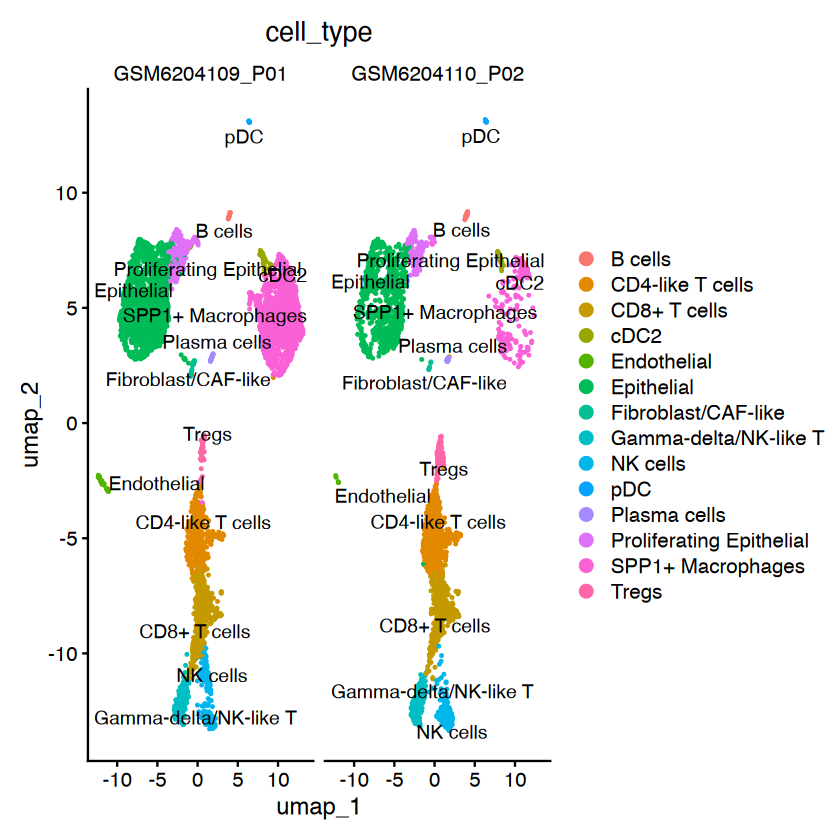

In [24]:
DimPlot(
    prechemo_integrated,
    reduction = "umap",
    group.by = "cell_type",
    split.by = "sample_id",
    label = TRUE,
    repel = TRUE
)

In [25]:
results_path <- "../Results/PreChemo"

dir.create(
    results_path,
    recursive = TRUE,
    showWarnings = FALSE
)

saveRDS(
    prechemo_integrated,
    file.path(results_path, "prechemo_annotated.rds")
)

write.csv(
    prechemo_markers,
    file.path(results_path, "prechemo_cluster_markers.csv"),
    row.names = FALSE
)

write.csv(
    top10_prechemo,
    file.path(results_path, "prechemo_top10_markers.csv"),
    row.names = FALSE
)

p_celltypes <- DimPlot(
    prechemo_integrated,
    reduction = "umap",
    group.by = "cell_type",
    label = TRUE,
    repel = TRUE,
    label.size = 3.5
) +
    NoLegend() +
    ggtitle("Pre-Chemotherapy PDAC: Annotated Cell Populations") +
    theme_classic(base_size = 13) +
    theme(
        plot.title = element_text(
            face = "bold",
            hjust = 0.5
        )
    )

ggsave(
    filename = file.path(results_path, "prechemo_annotated_umap.png"),
    plot = p_celltypes,
    width = 13,
    height = 9,
    dpi = 300,
    bg = "white"
)

if (exists("p_dot")) {

    ggsave(
        filename = file.path(results_path, "prechemo_celltype_dotplot.png"),
        plot = p_dot,
        width = 19,
        height = 9,
        dpi = 300,
        bg = "white"
    )

} else {
    message("p_dot not found. Skipping DotPlot export.")
}

list.files(results_path)

[1] "prechemo_annotated_umap.png"   "prechemo_annotated.rds"       
[3] "prechemo_celltype_dotplot.png" "prechemo_cluster_markers.csv" 
[5] "prechemo_top10_markers.csv"

In [26]:
integration_features_postchemo <- SelectIntegrationFeatures(post_chemo, nfeatures=2000)

In [27]:
anchors_postchemo <- FindIntegrationAnchors(post_chemo, anchor.features=integration_features_postchemo, dims=1:30)

Warning message in CheckDuplicateCellNames(object.list = object.list):
“Some cell names are duplicated across objects provided. Renaming to enforce unique cell names.”
Scaling features for provided objects

Finding all pairwise anchors

Running CCA

Using RSpectra for CCA since the cell-by-cell cross-product matrix has at least 1,000,000 entries.
To use irlba, set `svd.method = "irlba"`
Merging objects

Finding neighborhoods

Finding anchors

	Found 4089 anchors

Filtering anchors

	Retained 3016 anchors



In [28]:
postchemo_integrated <- IntegrateData(anchors_postchemo, dims=1:30)

Merging dataset 2 into 1

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”


In [29]:
DefaultAssay(postchemo_integrated) <- "integrated"

In [30]:
postchemo_integrated <- ScaleData(postchemo_integrated)
postchemo_integrated <- RunPCA(postchemo_integrated, npcs=30)

Centering and scaling data matrix

PC_ 1 
Positive:  KRT19, SPINT2, EPCAM, C19orf33, KRT8, S100A14, CEACAM6, TM4SF1, FXYD3, S100P 
	   TSPAN8, MAL2, DSG2, LAMB3, IFI27, ITGA6, KRT18, AGR2, OCIAD2, LCN2 
	   SLPI, CLDN4, TSPAN1, S100A6, KRT7, PERP, COL17A1, ANXA2, LMO7, SERPINA3 
Negative:  VIM, SPARC, DCN, FN1, BGN, COL6A3, LUM, COL3A1, COL1A2, VCAN 
	   SFRP2, COL1A1, SERPINF1, COL5A2, THBS2, MMP2, AEBP1, PLXDC2, CTHRC1, MGP 
	   INHBA, SULF1, IGFBP7, C11orf96, CALD1, ASPN, FBLN1, THY1, TAGLN, C1S 
PC_ 2 
Positive:  CALD1, DCN, LUM, COL1A2, COL3A1, COL6A3, BGN, COL1A1, SFRP2, IGFBP7 
	   SPARC, COL5A2, THBS2, CTHRC1, COL6A2, RARRES2, AEBP1, SULF1, C1S, MMP2 
	   COL6A1, FBLN1, IGFBP4, THY1, C1R, NNMT, ASPN, CCDC80, FBN1, MGP 
Negative:  TYROBP, SRGN, HLA-DRA, IFI30, LAPTM5, FCER1G, HLA-DPA1, CD74, HLA-DPB1, HLA-DRB1 
	   AIF1, ALOX5AP, LCP1, FCGR2A, LYZ, HLA-DQB1, C1QA, CYBB, MSR1, FCGR3A 
	   MS4A7, RGS1, SLC11A1, MS4A6A, GPR183, CD68, HLA-DRB5, SPP1, C5AR1, C1QB 
PC_ 3 
Positive:  C

In [31]:
postchemo_integrated <- RunUMAP(postchemo_integrated, dims=1:30, n.neighbors = 30, min.dist=0.3)

16:44:45 UMAP embedding parameters a = 0.9922 b = 1.112

16:44:45 Read 15252 rows and found 30 numeric columns

16:44:45 Using Annoy for neighbor search, n_neighbors = 30

16:44:45 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:44:46 Writing NN index file to temp file /var/folders/s0/b80lx8jj2d70y40_0dnz9c680000gn/T//RtmpB9bf5V/file65606d9567ef

16:44:46 Searching Annoy index using 1 thread, search_k = 3000

16:44:48 Annoy recall = 100%

16:44:49 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:44:50 Initializing from normalized Laplacian + noise (using RSpectra)

16:44:50 Commencing optimization for 200 epochs, with 664430 positive edges

16:44:50 Using rng type: pcg

16:44:56 Optimization finished



In [32]:
postchemo_integrated <- FindNeighbors(postchemo_integrated, dims=1:30)

Computing nearest neighbor graph

Computing SNN



In [33]:
postchemo_integrated <- FindClusters(postchemo_integrated, resolution=0.3, algorithm=3)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 15252
Number of edges: 551388

Running smart local moving algorithm...
Maximum modularity in 10 random starts: 0.9494
Number of communities: 18
Elapsed time: 7 seconds


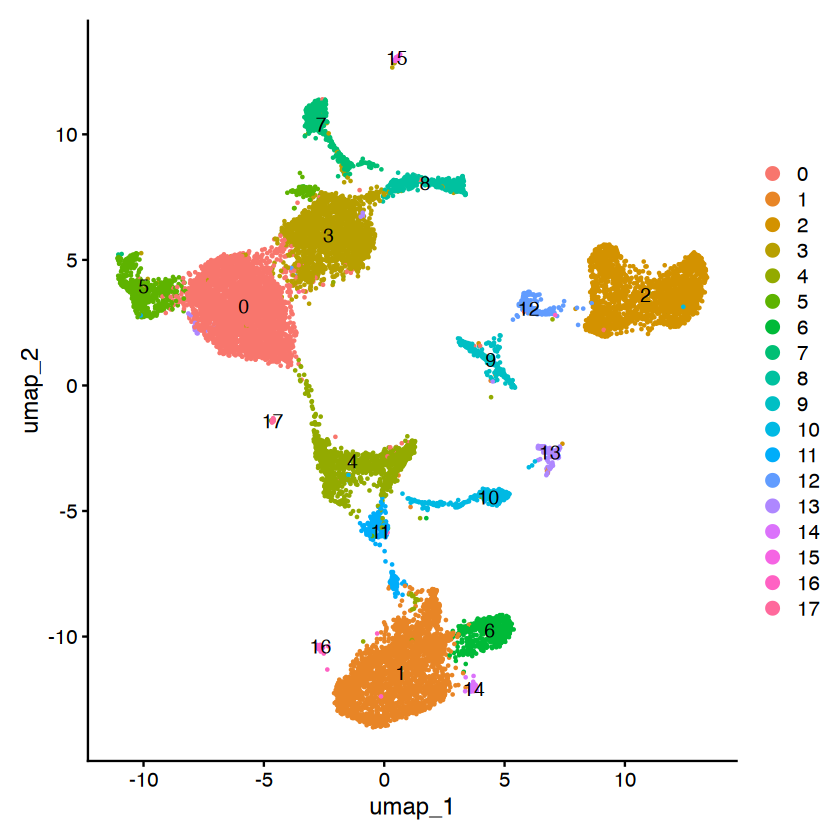

In [34]:
DimPlot(postchemo_integrated, reduction="umap", label=TRUE)

In [35]:
DefaultAssay(postchemo_integrated) <- "RNA"

postchemo_integrated <- JoinLayers(postchemo_integrated, assay = "RNA")

postchemo_markers <- FindAllMarkers(postchemo_integrated, only.pos=TRUE, min.pct = 0.25, logfc.threshold = 0.25, test.use='wilcox')

Calculating marker statistics for 18 clusters using presto

  Calculating fold changes

  Running presto::wilcoxauc



In [36]:
top10_postchemo <- postchemo_markers %>%
    group_by(cluster) %>%
    slice_max(
        order_by = avg_log2FC,
        n = 10,
        with_ties = FALSE
    )

In [37]:
top10_postchemo

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,3.968045,0.655,0.107,0,0,MUCL3
0,3.314568,0.476,0.074,0,0,FAM83A
0,3.236589,0.871,0.220,0,0,DCBLD2
0,3.218875,0.403,0.066,0,0,KRT6A
0,3.056827,0.426,0.085,0,0,KRT6B
0,3.022068,0.300,0.044,0,0,SPRR1B
0,2.934687,0.875,0.220,0,0,COL17A1
0,2.919500,0.292,0.051,0,0,SCEL
0,2.902718,0.779,0.192,0,0,F3


In [42]:
write.csv(
    top10_postchemo,
    "../Results/postchemo_top10_markers.csv",
    row.names = FALSE
)

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


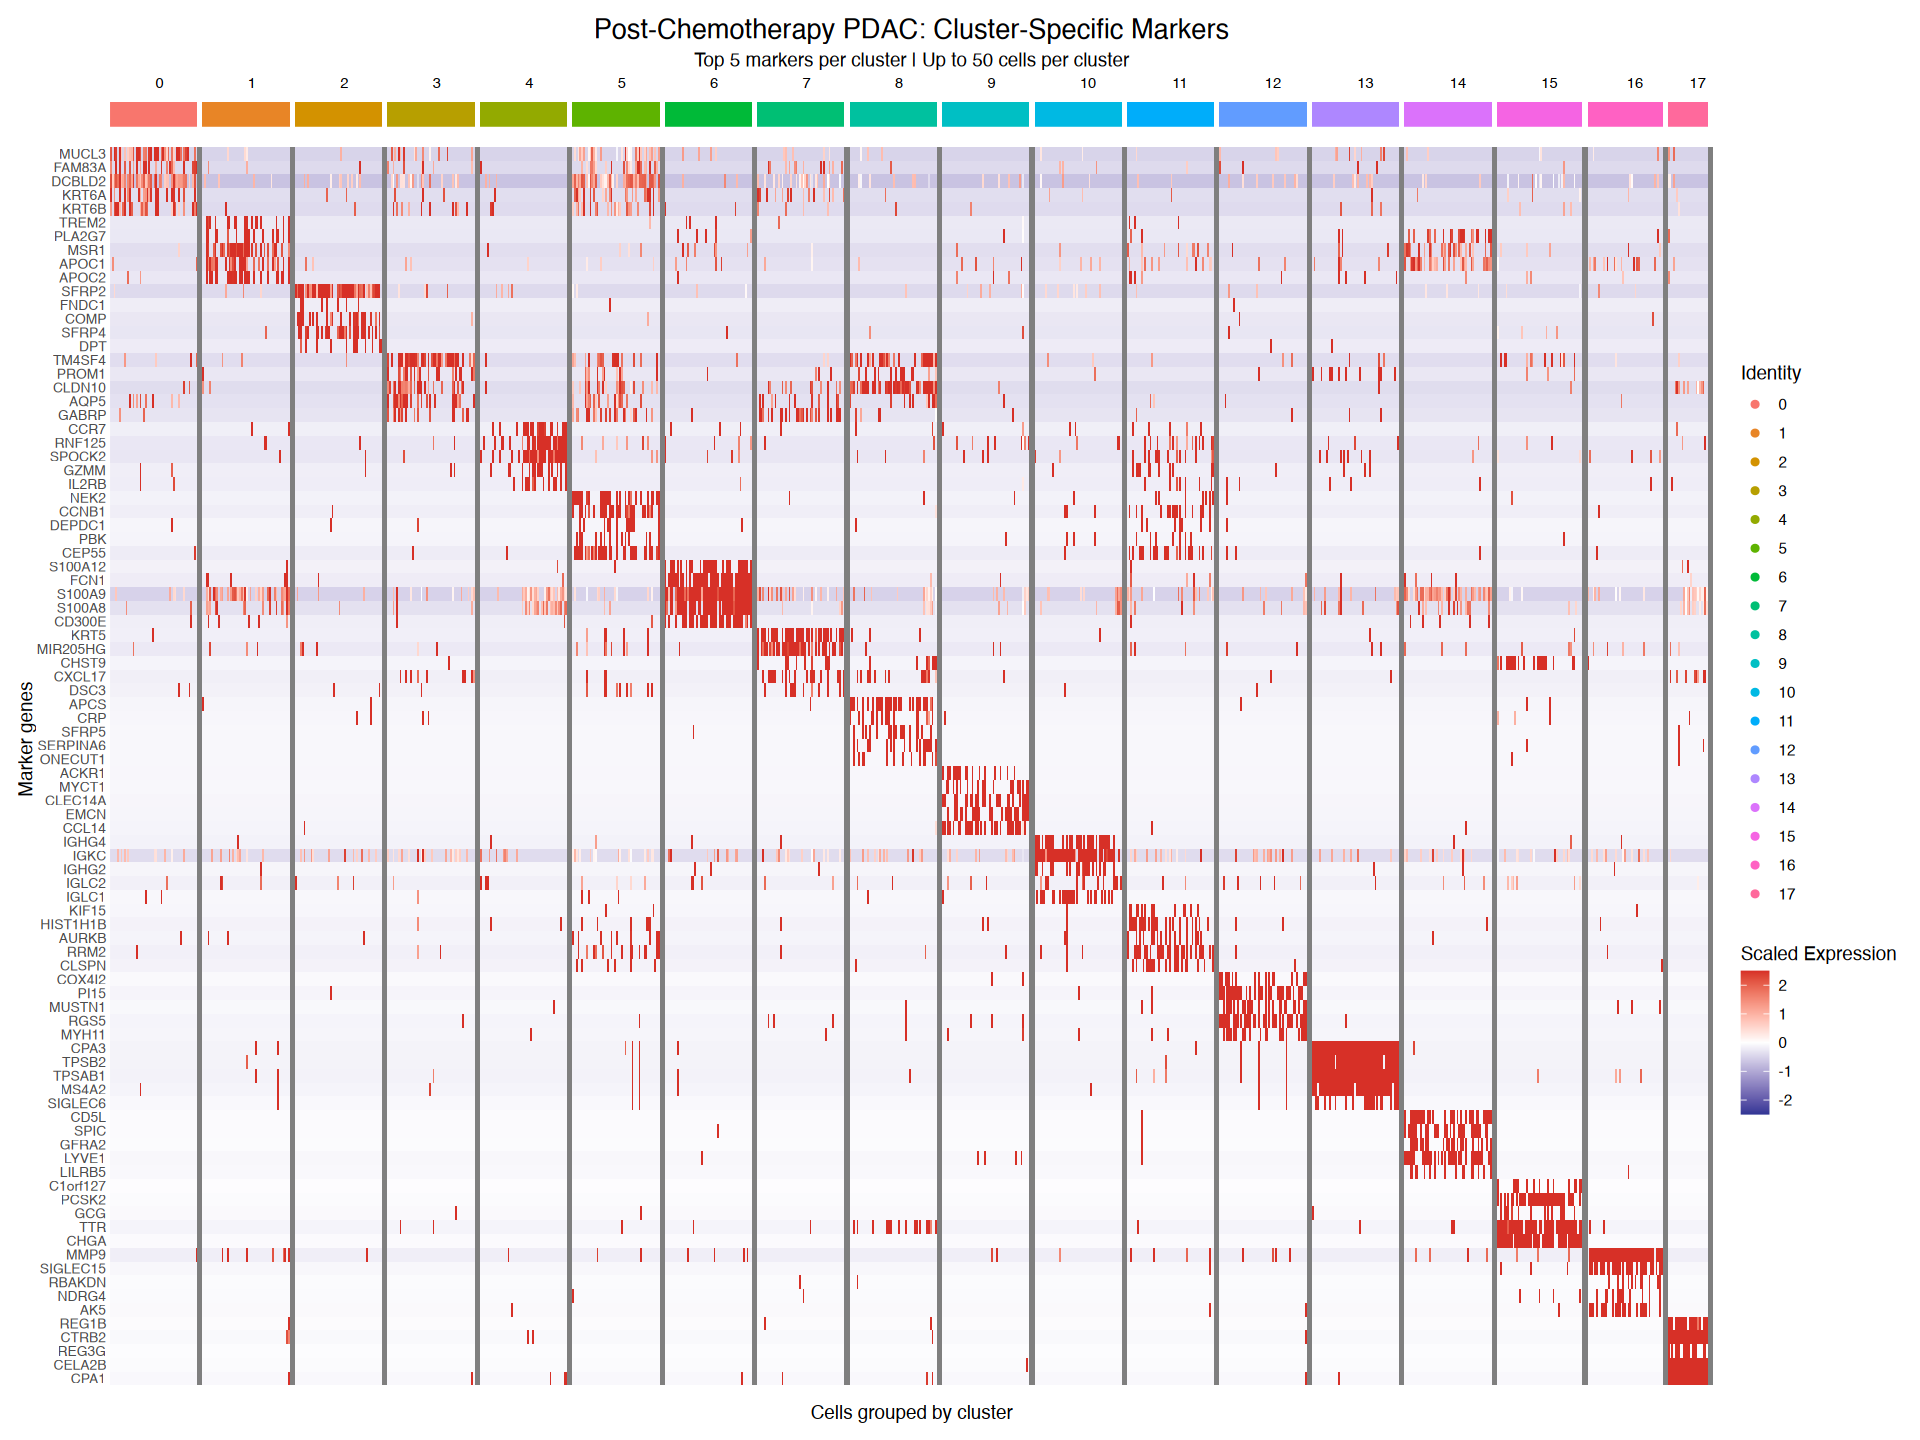

In [39]:
# Select top 5 statistically significant markers per cluster
top5_postchemo <- postchemo_markers %>%
    filter(p_val_adj < 0.05) %>%
    group_by(cluster) %>%
    slice_max(
        order_by = avg_log2FC,
        n = 5,
        with_ties = FALSE
    ) %>%
    ungroup()

# Scale selected genes in the RNA assay for the heatmap
DefaultAssay(postchemo_integrated) <- "RNA"

postchemo_integrated <- ScaleData(
    postchemo_integrated,
    features = unique(top5_postchemo$gene)
)

# Downsample cells
set.seed(42)

postchemo_subset <- subset(
    postchemo_integrated,
    downsample = 50
)

# Create heatmap
p_heatmap_postchemo <- DoHeatmap(
    object = postchemo_subset,
    features = unique(top5_postchemo$gene),
    assay = "RNA",
    group.by = "seurat_clusters",
    size = 3,
    angle = 0,
    raster = TRUE
) +
    scale_fill_gradientn(
        colors = c("#313695", "#FFFFFF", "#D73027"),
        limits = c(-2.5, 2.5),
        oob = scales::squish
    ) +
    labs(
        title = "Post-Chemotherapy PDAC: Cluster-Specific Markers",
        subtitle = "Top 5 markers per cluster | Up to 50 cells per cluster",
        x = "Cells grouped by cluster",
        y = "Marker genes",
        fill = "Scaled Expression"
    ) +
    theme(
        plot.title = element_text(
            size = 16,
            face = "bold",
            hjust = 0.5
        ),
        plot.subtitle = element_text(
            size = 11,
            hjust = 0.5
        ),
        axis.text.y = element_text(size = 8),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        legend.position = "right"
    )

options(
    repr.plot.width = 16,
    repr.plot.height = 12
)

p_heatmap_postchemo

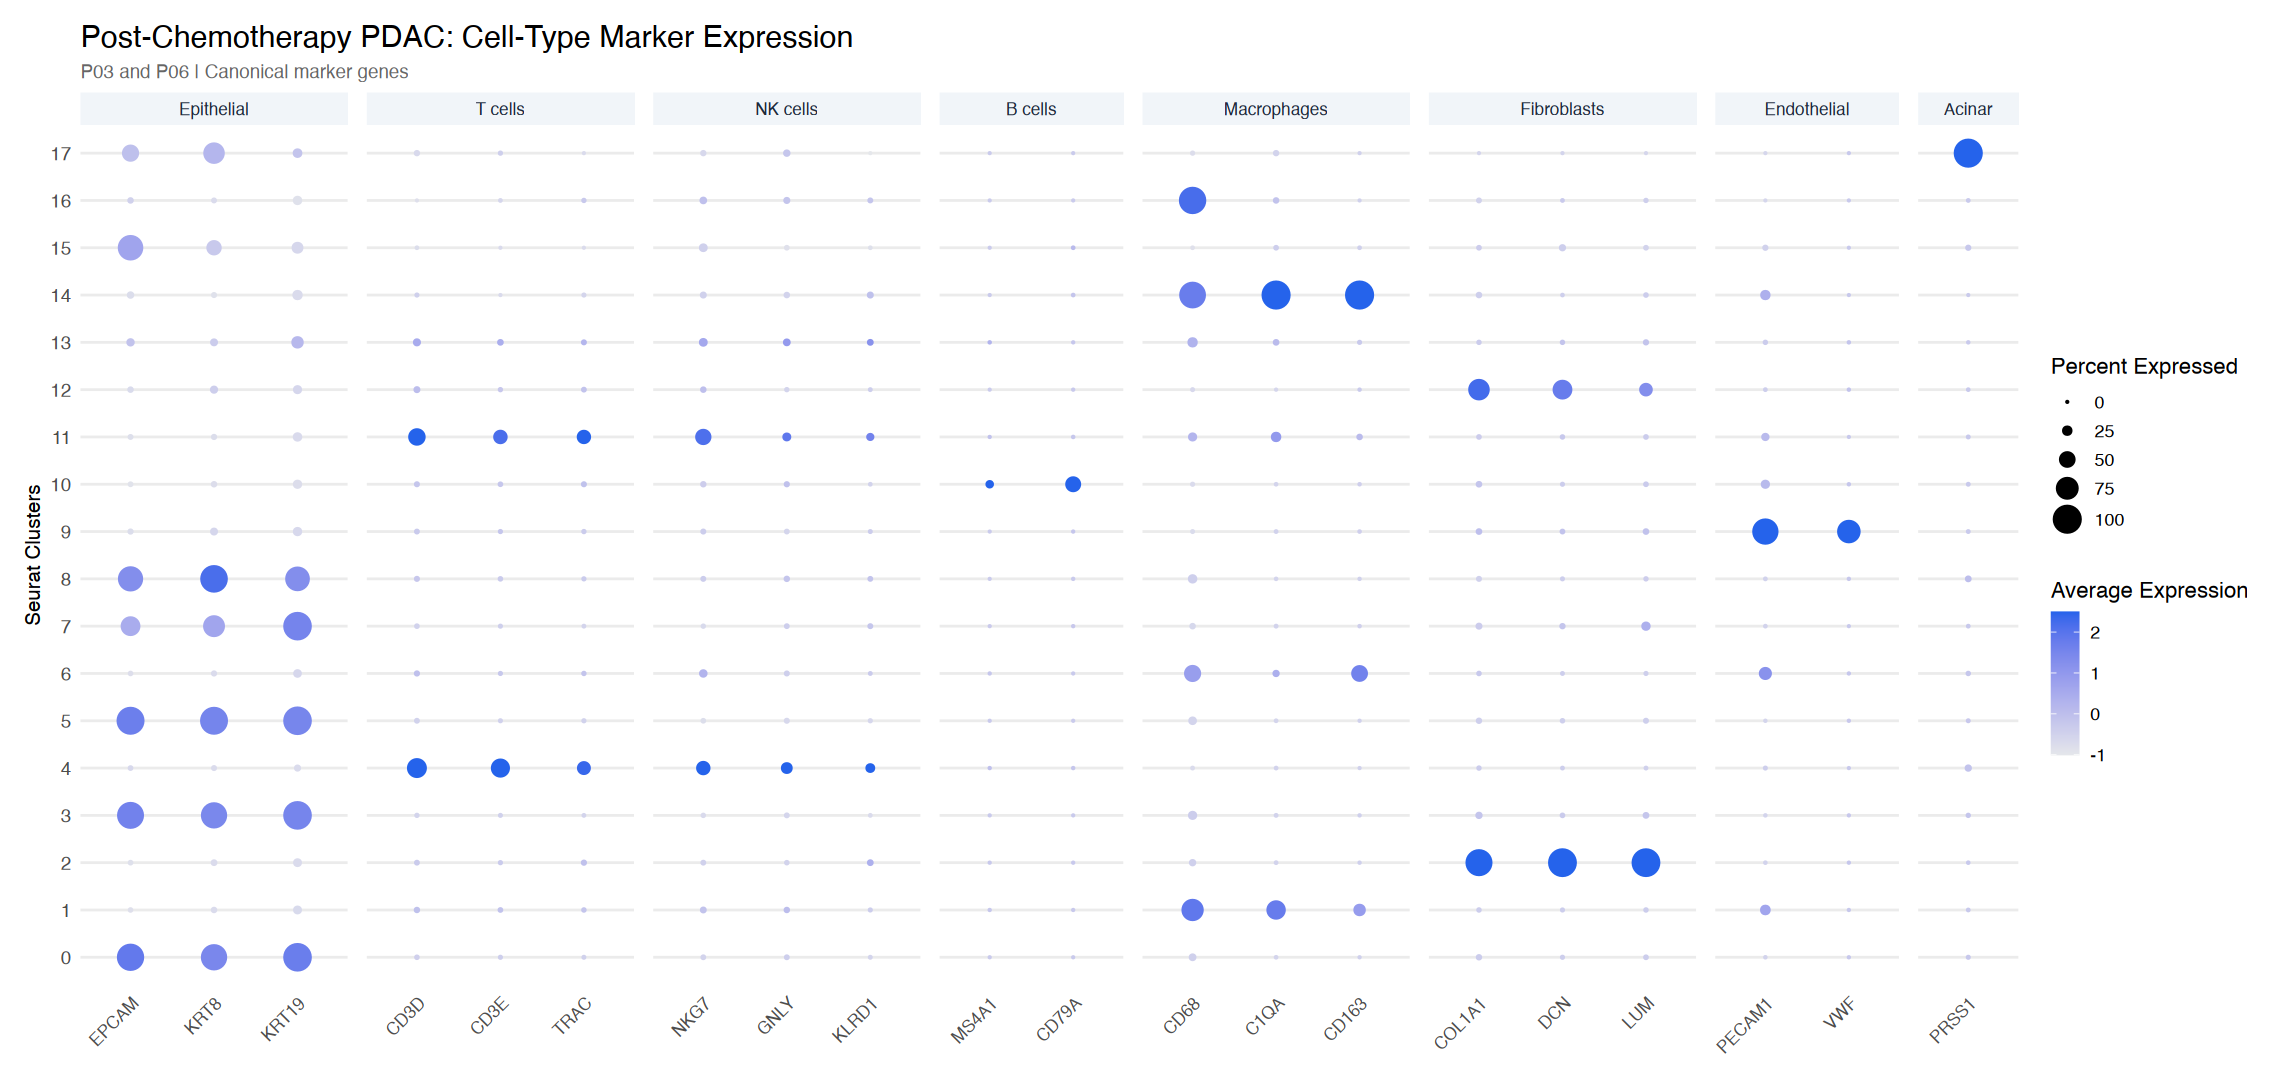

In [40]:
library(ggplot2)

celltype_markers <- list(
    "Epithelial"  = c("EPCAM", "KRT8", "KRT19"),
    "T cells"     = c("CD3D", "CD3E", "TRAC"),
    "NK cells"    = c("NKG7", "GNLY", "KLRD1"),
    "B cells"     = c("MS4A1", "CD79A"),
    "Macrophages" = c("CD68", "C1QA", "CD163"),
    "Fibroblasts" = c("COL1A1", "DCN", "LUM"),
    "Endothelial" = c("PECAM1", "VWF"),
    "Acinar"      = c("PRSS1")
)

# Keep only genes available in the dataset
celltype_markers <- lapply(
    celltype_markers,
    function(x) intersect(x, rownames(postchemo_integrated))
)

celltype_markers <- Filter(
    function(x) length(x) > 0,
    celltype_markers
)

p_dot_postchemo <- DotPlot(
    object = postchemo_integrated,
    features = celltype_markers,
    assay = "RNA",
    group.by = "seurat_clusters",
    dot.scale = 7,
    cols = c("#E5E7EB", "#2563EB")
) +
    labs(
        title = "Post-Chemotherapy PDAC: Cell-Type Marker Expression",
        subtitle = "P03 and P06 | Canonical marker genes",
        x = NULL,
        y = "Seurat Clusters",
        color = "Average Expression",
        size = "Percent Expressed"
    ) +
    theme_minimal(base_size = 13) +
    theme(
        plot.title = element_text(
            size = 18,
            face = "bold"
        ),
        plot.subtitle = element_text(
            size = 11,
            color = "grey40"
        ),
        strip.text.x = element_text(
            size = 10,
            face = "bold",
            color = "#1E293B"
        ),
        strip.background = element_rect(
            fill = "#F1F5F9",
            color = NA
        ),
        axis.text.x = element_text(
            angle = 45,
            hjust = 1,
            vjust = 1,
            size = 10,
            face = "bold"
        ),
        axis.text.y = element_text(size = 11),
        axis.title.y = element_text(
            size = 12,
            face = "bold"
        ),
        panel.grid.major.x = element_blank(),
        panel.grid.minor = element_blank(),
        panel.spacing.x = grid::unit(0.8, "lines"),
        legend.position = "right",
        plot.margin = margin(15, 15, 15, 15)
    )

options(
    repr.plot.width = 19,
    repr.plot.height = 9,
    repr.plot.res = 120
)

p_dot_postchemo

In [ ]:
cluster_annotations_postchemo <- c(
    "0"  = "Basal-like Epithelial 1",
    "1"  = "TREM2+ Macrophages",
    "2"  = "CAFs",
    "3"  = "Ductal Epithelial",
    "4"  = "T/NK Lymphocytes",
    "5"  = "Proliferating 1",
    "6"  = "Inflammatory Monocytes",
    "7"  = "Basal-like Epithelial 2",
    "8"  = "Secretory-like (Uncertain)",
    "9"  = "Endothelial",
    "10" = "Plasma cells",
    "11" = "Proliferating (Unknown)",
    "12" = "Pericytes/VSMCs",
    "13" = "Mast cells",
    "14" = "LYVE1+ Macrophages",
    "15" = "Endocrine cells",
    "16" = "Osteoclast-like Macrophages",
    "17" = "Acinar cells"
)

postchemo_integrated$cell_type <- unname(
    cluster_annotations_postchemo[
        as.character(postchemo_integrated$seurat_clusters)
    ]
)

table(postchemo_integrated$cell_type, useNA = "ifany")


               Acinar cells     Basal-like Epithelial 1 
                         23                        3459 
    Basal-like Epithelial 2                        CAFs 
                        482                        2188 
          Ductal Epithelial             Endocrine cells 
                       2110                          49 
                Endothelial      Inflammatory Monocytes 
                        370                         493 
         LYVE1+ Macrophages                  Mast cells 
                         53                         180 
Osteoclast-like Macrophages             Pericytes/VSMCs 
                         43                         214 
               Plasma cells             Proliferating 1 
                        325                         640 
            Proliferating 2  Secretory-like (Uncertain) 
                        233                         412 
           T/NK Lymphocytes          TREM2+ Macrophages 
                       1240   

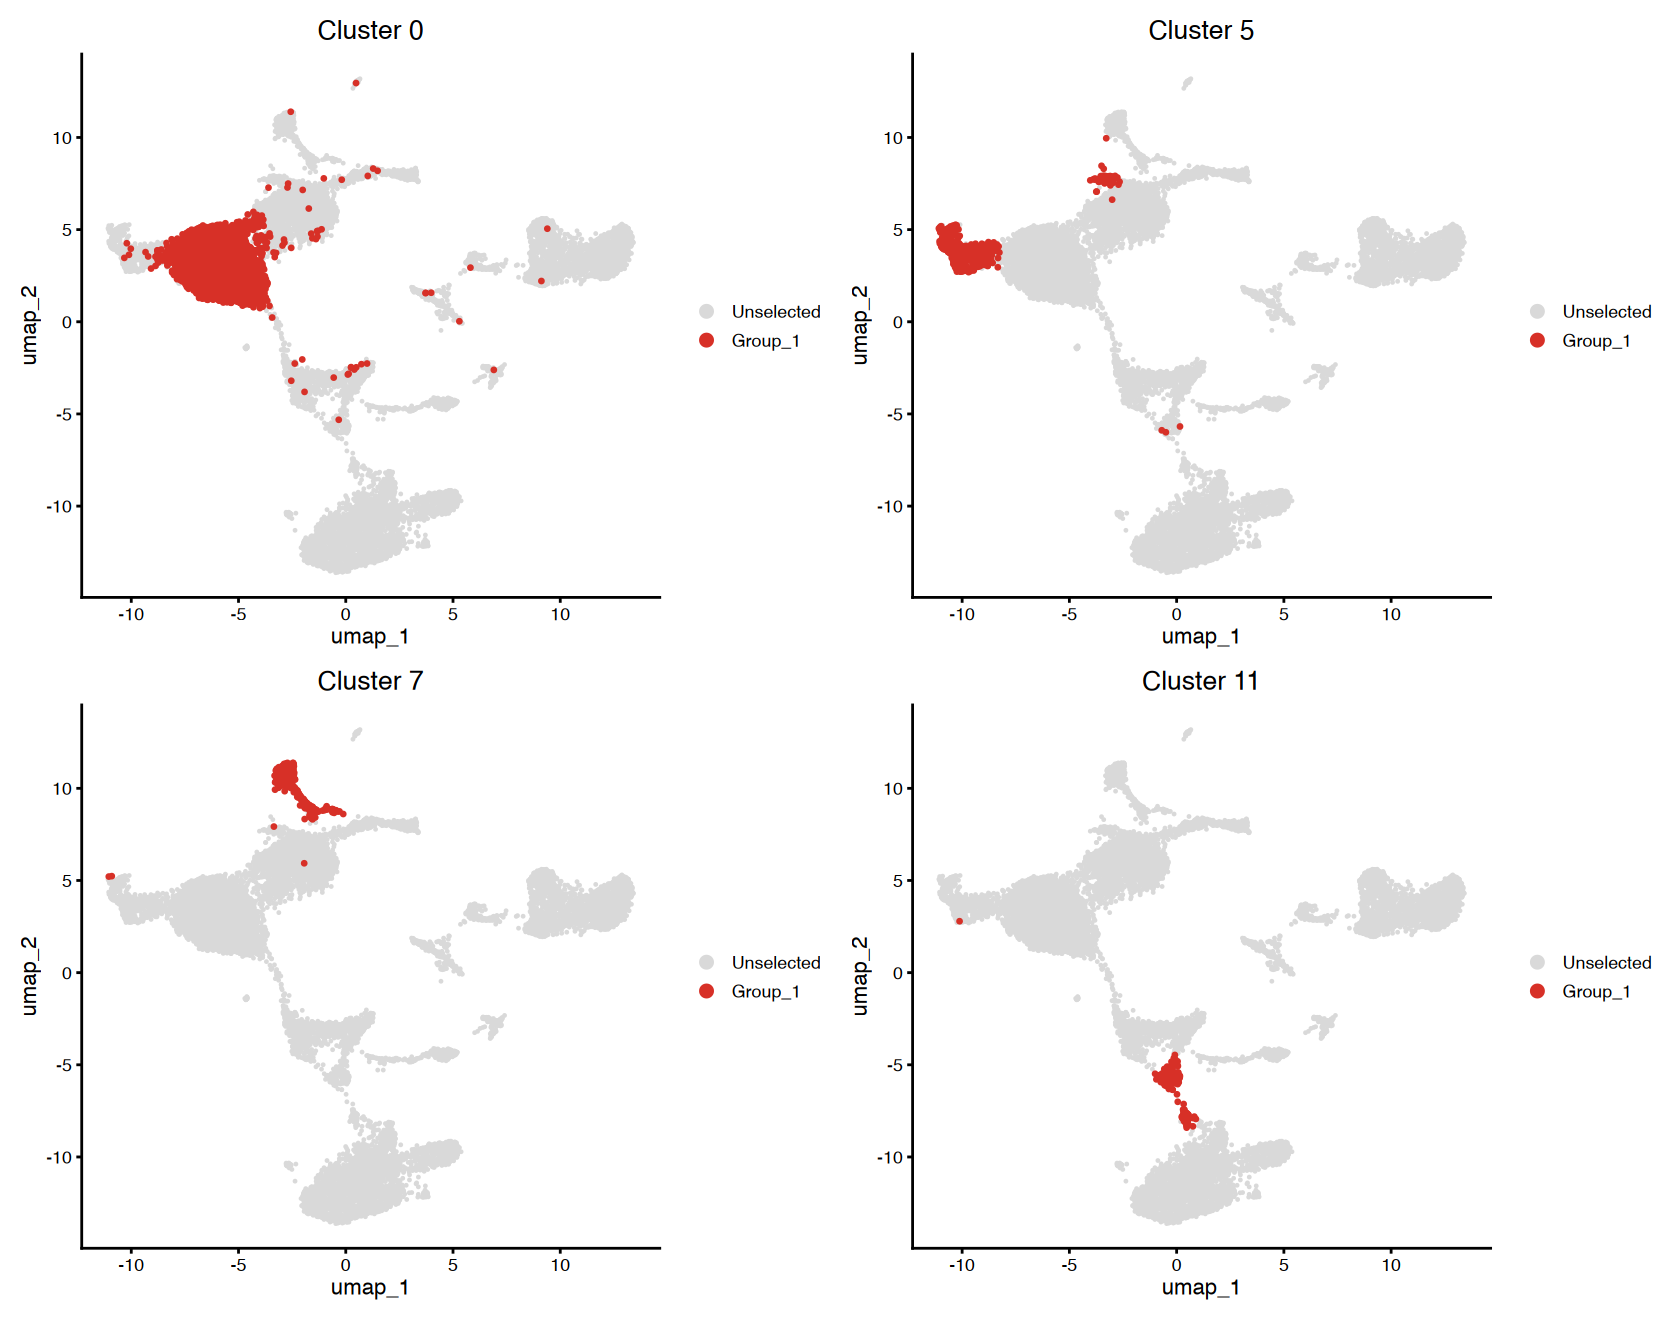

In [44]:
# Make sure cluster identities are active
Idents(postchemo_integrated) <- "seurat_clusters"

clusters <- c("0", "5", "7", "11")

p_clusters <- lapply(clusters, function(cl) {

    cells <- WhichCells(
        postchemo_integrated,
        idents = cl
    )

    DimPlot(
        postchemo_integrated,
        reduction = "umap",
        cells.highlight = cells,
        cols = "grey85",
        cols.highlight = "#D73027",
        sizes.highlight = 0.7,
        pt.size = 0.15
    ) +
        ggtitle(paste("Cluster", cl)) +
        NoLegend() +
        theme_classic(base_size = 13) +
        theme(
            plot.title = element_text(
                face = "bold",
                hjust = 0.5
            )
        )
})

options(
    repr.plot.width = 14,
    repr.plot.height = 11
)

wrap_plots(p_clusters, ncol = 2)

In [45]:
DefaultAssay(postchemo_integrated) <- "RNA"

Idents(postchemo_integrated) <- "seurat_clusters"

# Extract cluster 11
cluster11 <- subset(
    postchemo_integrated,
    idents = "11"
)

# Average normalized expression
AverageExpression(
    cluster11,
    features = c(
        "EPCAM", "KRT8", "KRT18", "KRT19",
        "PTPRC", "CD3D", "CD68",
        "MKI67", "TOP2A"
    ),
    assays = "RNA",
    layer = "data"
)$RNA

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
The following grouping variables have 1 value and will be ignored: ident

All grouping variables have 1 value only. Computing across all cells.



9 x 1 sparse Matrix of class "dgCMatrix"
                
PTPRC 17.9019307
EPCAM  0.2601509
MKI67 10.2395263
CD3D   3.9758639
KRT8   0.3390521
KRT18  0.2625211
CD68   1.4331940
TOP2A  6.6783227
KRT19  0.8914339

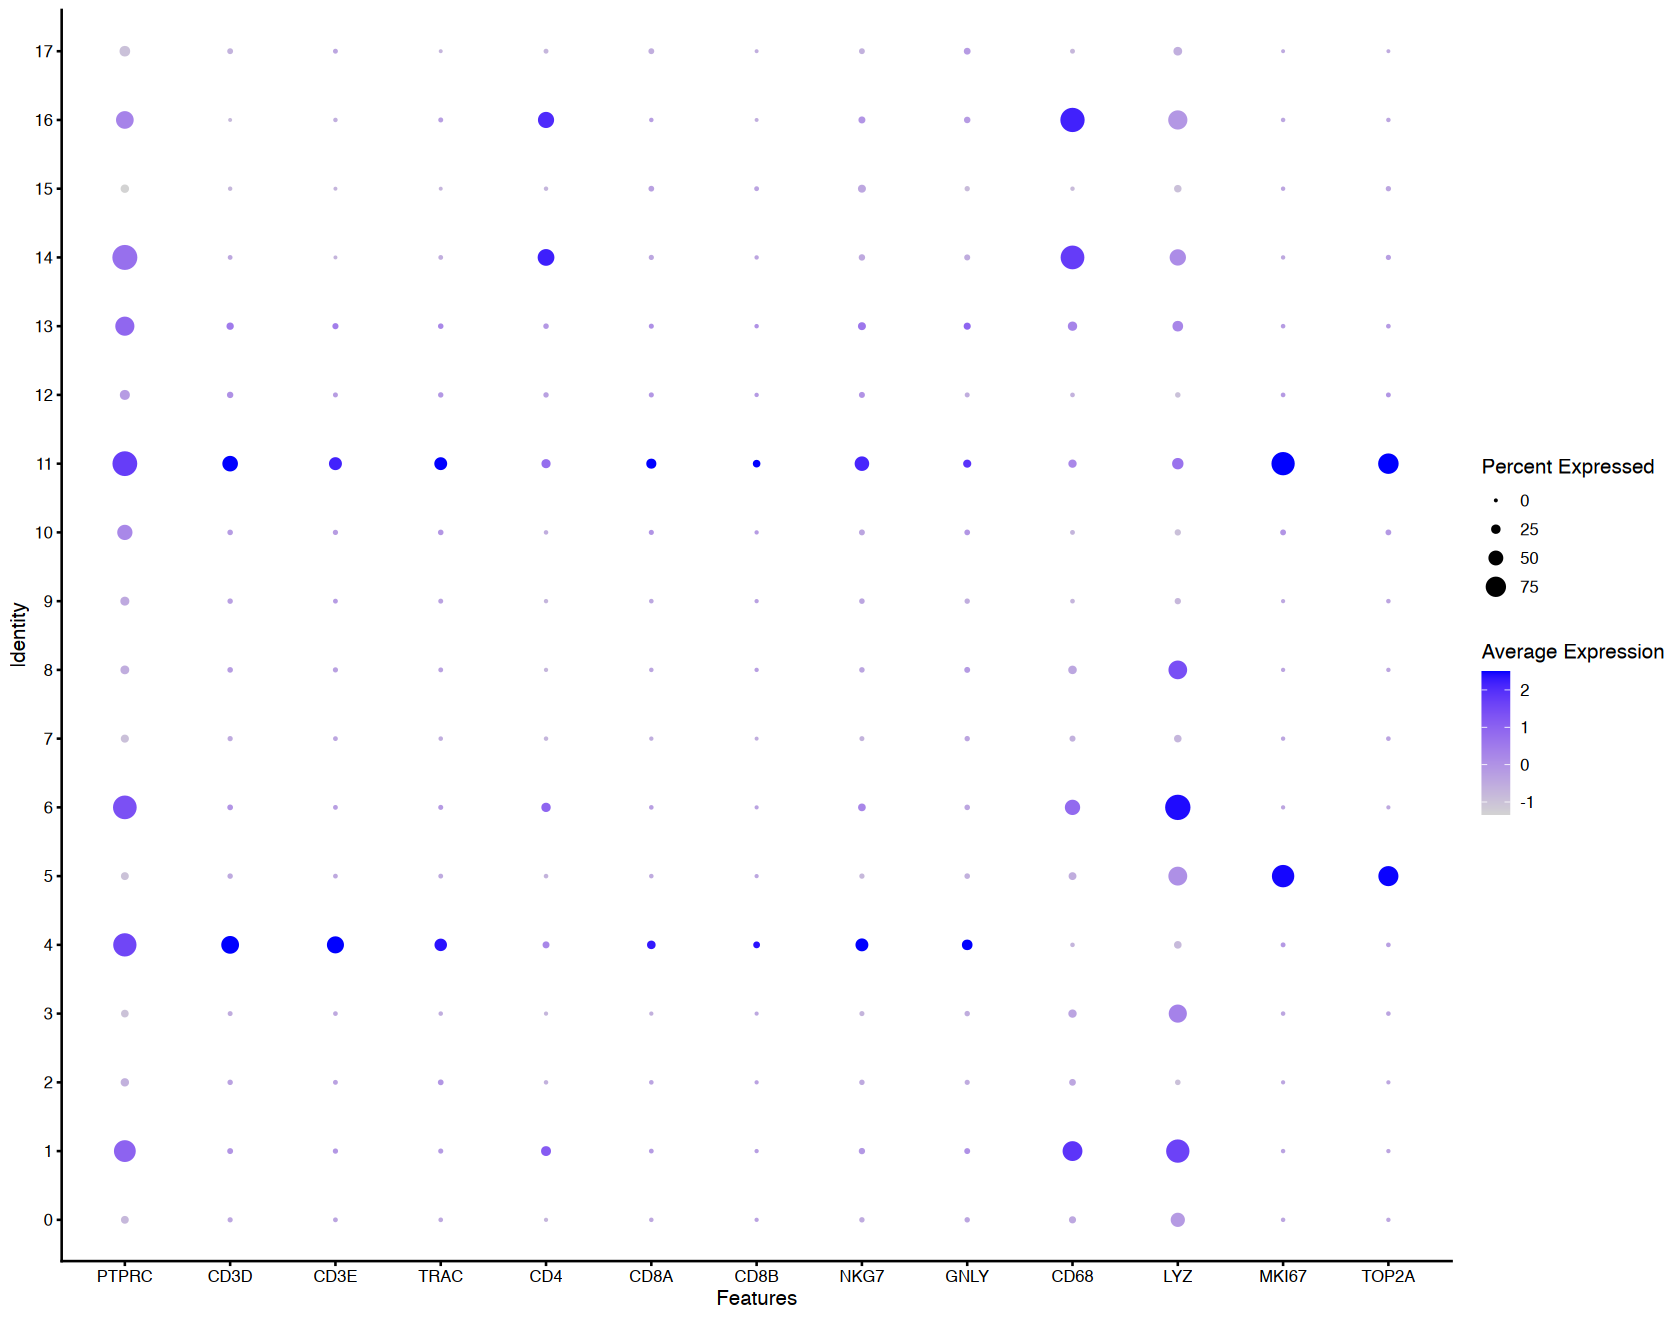

In [46]:
DefaultAssay(postchemo_integrated) <- "RNA"

Idents(postchemo_integrated) <- "seurat_clusters"

markers <- c(
    "PTPRC", "CD3D", "CD3E", "TRAC",
    "CD4", "CD8A", "CD8B",
    "NKG7", "GNLY",
    "CD68", "LYZ",
    "MKI67", "TOP2A"
)

markers <- intersect(
    markers,
    rownames(postchemo_integrated)
)

DotPlot(
    postchemo_integrated,
    features = markers,
    group.by = "seurat_clusters",
    assay = "RNA"
) +
    RotatedAxis() +
    theme_classic(base_size = 12)

In [47]:
cluster_annotations_postchemo[
    c("0", "3", "5", "7", "8")
] <- "Epithelial cells"

# Keep cluster 11 as proliferating T cells
cluster_annotations_postchemo["11"] <- "Proliferating T cells"

# Update Seurat metadata
postchemo_integrated$cell_type <- unname(
    cluster_annotations_postchemo[
        as.character(postchemo_integrated$seurat_clusters)
    ]
)

In [48]:
results_path <- "../Results/PostChemo"

dir.create(
    results_path,
    recursive = TRUE,
    showWarnings = FALSE
)

saveRDS(
    postchemo_integrated,
    file.path(results_path, "postchemo_annotated.rds")
)

# All differentially expressed genes
write.csv(
    postchemo_markers,
    file.path(results_path, "postchemo_cluster_markers.csv"),
    row.names = FALSE
)

# Top 10 markers per cluster
write.csv(
    top10_postchemo,
    file.path(results_path, "postchemo_top10_markers.csv"),
    row.names = FALSE
)

# Cluster-to-cell-type mapping
write.csv(
    data.frame(
        cluster = names(cluster_annotations_postchemo),
        cell_type = unname(cluster_annotations_postchemo)
    ),
    file.path(results_path, "postchemo_annotations.csv"),
    row.names = FALSE
)

p_celltypes_postchemo <- DimPlot(
    postchemo_integrated,
    reduction = "umap",
    group.by = "cell_type",
    label = TRUE,
    repel = TRUE,
    label.size = 3
) +
    ggtitle("Post-Chemotherapy PDAC: Cell-Type Annotation") +
    theme_classic(base_size = 13) +
    theme(
        plot.title = element_text(
            face = "bold",
            hjust = 0.5
        )
    )

ggsave(
    filename = file.path(
        results_path,
        "postchemo_annotated_umap.png"
    ),
    plot = p_celltypes_postchemo,
    width = 15,
    height = 10,
    dpi = 300,
    bg = "white"
)

if (exists("p_dot_postchemo")) {

    ggsave(
        filename = file.path(
            results_path,
            "postchemo_celltype_dotplot.png"
        ),
        plot = p_dot_postchemo,
        width = 19,
        height = 9,
        dpi = 300,
        bg = "white"
    )
}

if (exists("p_heatmap_postchemo")) {

    ggsave(
        filename = file.path(
            results_path,
            "postchemo_markers_heatmap.png"
        ),
        plot = p_heatmap_postchemo,
        width = 16,
        height = 12,
        dpi = 300,
        bg = "white"
    )
}

list.files(results_path)

[1] "postchemo_annotated_umap.png"   "postchemo_annotated.rds"       
[3] "postchemo_annotations.csv"      "postchemo_celltype_dotplot.png"
[5] "postchemo_cluster_markers.csv"  "postchemo_markers_heatmap.png" 
[7] "postchemo_top10_markers.csv"